# 12 — Which background sets the threshold? (unified threshold convention)

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** The report quotes ρ₅₀ of the matched-filter bank as 5.5 (section 4, threshold from the *training* background) and 4.9 (sections 6 and 8, threshold from the *validation* background). Here the same bank and the same sine-Gaussian / pulse / chirp injections are evaluated with the threshold taken from the train, the validation, the pooled train+validation and the test noise, at FAP 10⁻² and 10⁻³, with bootstrap errors (notebook 11 helpers). It fixes the **convention**: all cross-method comparisons use the validation background; the training-background numbers are kept only for the calibration discussion.

**What it does not do.** It does not retrain or change any detector, and it does not choose the "right" background: the test noise is never used to set a threshold in the headline numbers (it is shown only to quantify the epoch dependence).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gwosc_tools as g
g.style()
rng = np.random.default_rng(12)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
banks = {i: g.SGBank(CH[i]["S1"]) for i in CH}
V, ID = {}, {}
for sp in ("train", "val", "test"):
    V[sp], ID[sp], _ = g.load_split(sp)
S1te = np.stack([CH[i]["S1"] for i in ID["test"]])
def cached_scan(name, v, cid):
    fn = os.path.join(g.CACHE, f"scan03_{name}.npz")
    if os.path.exists(fn):
        d = np.load(fn); return {k: d[k] for k in d.files}
    o = g.scan_mixed(v, cid, banks); np.savez_compressed(fn, **o); return o
BK = {sp: cached_scan(sp, V[sp], ID[sp])["rho2"] for sp in ("train", "val", "test")}
BK["train+val"] = np.concatenate([BK["train"], BK["val"]])
print({k: len(v) for k, v in BK.items()})

{'train': 16224, 'val': 8112, 'test': 8112, 'train+val': 24336}


In [2]:
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; NINJ = 500
fn = os.path.join(g.CACHE, "inj12.npz")
if os.path.exists(fn):
    d = np.load(fn); INJ = {tuple([k.split("|")[0], int(k.split("|")[1])]): d[k] for k in d.files}
else:
    INJ = {}
    for kind in g.MORPHS:
        for snr in SNRS:
            idx = rng.choice(len(V["test"]), NINJ, replace=False)
            ser, _, _ = g.inject(V["test"][idx], kind, float(snr), rng, S1te[idx])
            INJ[(kind, snr)] = g.scan_mixed(ser, ID["test"][idx], banks)["rho2"]
    np.savez_compressed(fn, **{f"{k}|{s}": v for (k, s), v in INJ.items()})
print(len(INJ), "injection sets")

33 injection sets


In [3]:
rows = []
for bk in ("train", "val", "train+val", "test"):
    for far in (1e-2, 1e-3):
        for kind in g.MORPHS:
            p, b = g.bootstrap_rho(BK[bk], [INJ[(kind, s)] for s in SNRS], SNRS, far, B=300, seed=3)
            rows.append(dict(background=bk, FAP=far, morph=kind, rho50=p[0], err50=(g.ci(b[:, 0])[1] - g.ci(b[:, 0])[0]) / 2, rho90=p[1], thr=g.threshold_at_far(BK[bk], far)))
R = pd.DataFrame(rows)
T = R.pivot_table(index=["FAP", "background"], columns="morph", values="rho50"); T["mean"] = T.mean(1); T.round(2)

morph             chirp  pulse     sg   mean
FAP   background                            
0.001 test          NaN  15.16  14.16  14.66
      train       14.06  11.38  10.78  12.07
      train+val   13.33  10.83  10.08  11.41
      val          9.08   7.39   6.82   7.76
0.010 test         6.18   5.36   4.89   5.48
      train        7.05   5.87   5.49   6.13
      train+val    6.78   5.64   5.27   5.90
      val          6.25   5.40   4.94   5.53

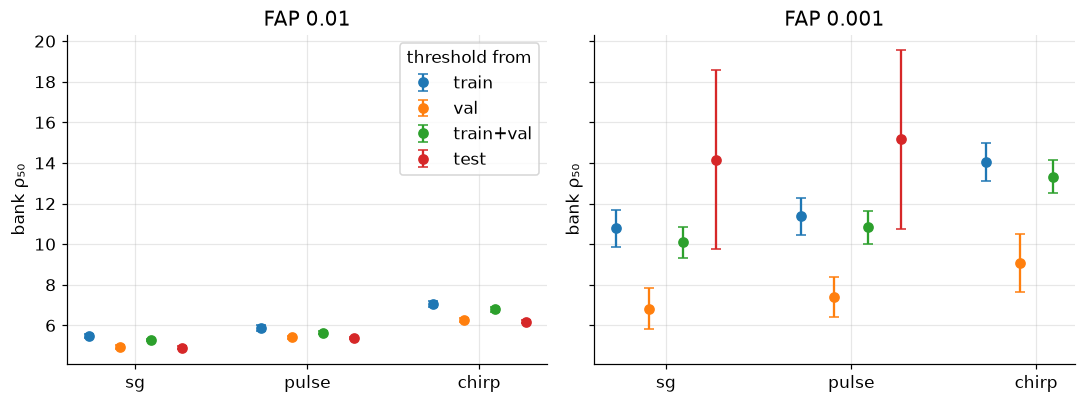

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for a, far in zip(ax, (1e-2, 1e-3)):
    for j, bk in enumerate(("train", "val", "train+val", "test")):
        s = R[(R.FAP == far) & (R.background == bk)]
        a.errorbar(np.arange(3) + 0.18 * (j - 1.5), s.rho50, s.err50, fmt="o", capsize=3, label=bk)
    a.set_xticks(range(3)); a.set_xticklabels(g.MORPHS); a.set_title(f"FAP {far:g}"); a.set_ylabel("bank ρ₅₀")
ax[0].legend(title="threshold from")
fig.tight_layout(); g.savefig(fig, "fig12_threshold_convention"); plt.show()
g.save_json(dict(rows=R.to_dict("records")), "12_summary.json")

## Output and next step

`results/12_summary.json`, `figures/fig12_threshold_convention`. Convention adopted in the report: **validation background** for every cross-method table; training-background numbers only in the calibration discussion of section 4. Next: summary figure of ρ₅₀ for all methods (extension 64).